# ESTUDIO DE CRÍMENES - LOS ÁNGELES (2020 - Presente)

---

+ Ejecución sobre environment de "cofml".

![Alt text](charts/Captura%20de%20pantalla%202023-04-08%20a%20las%2020.59.29.png)

+ This dataset is intended for public access and use.
+ License: CC0 1.0 Universal

----

In [1]:
#-- Import libraries ------------------------------------------------
import datatable as dt
import pandas as pd
pd.set_option('display.max_columns', 500)

from datar import options 
options(import_names_conflict="silent")
from datar.all import *
from datar.dplyr import *

import datetime
#-- Limpiar nombres de columnas
import janitor

In [2]:
#--- Read data. It's a big file (177Mb)
#-- Read with fread and convert to pandas and clean names (janitor)
datcrime = dt.fread("./datos/LosAngeles_Crime_Data_from_2020_to_Present.csv").to_pandas().clean_names()

In [3]:
#--- Number of rows
nrow(datcrime)

694915

In [4]:
head(datcrime, n = 10)

,dr_no,date_rptd,date_occ,time_occ,area,area_name,rpt_dist_no,part_1_2,crm_cd,crm_cd_desc,mocodes,vict_age,vict_sex,vict_descent,premis_cd,premis_desc,weapon_used_cd,weapon_desc,status,status_desc,crm_cd_1,crm_cd_2,crm_cd_3,crm_cd_4,location,cross_street,lat,lon
,<int32>,<object>,<object>,<int32>,<int32>,<object>,<int32>,<int32>,<int32>,<object>,<object>,<int32>,<object>,<object>,<float64>,<object>,<float64>,<object>,<object>,<object>,<float64>,<float64>,<float64>,<float64>,<object>,<object>,<float64>,<float64>
0,10304468,01/08/2020 12:00:00 AM,01/08/2020 12:00:00 AM,2230,3,Southwest,377,2,624,BATTERY - SIMPLE ASSAULT,0444 0913,36,F,B,501.0,SINGLE FAMILY DWELLING,400.0,"STRONG-ARM (HANDS, FIST, FEET OR BODILY FORCE)",AO,Adult Other,624.0,NaN,NaN,NaN,1100 W 39TH PL,,34.0141,-118.2978
1,190101086,01/02/2020 12:00:00 AM,01/01/2020 12:00:00 AM,330,1,Central,163,2,624,BATTERY - SIMPLE ASSAULT,0416 1822 1414,25,M,H,102.0,SIDEWALK,500.0,UNKNOWN WEAPON/OTHER WEAPON,IC,Invest Cont,624.0,NaN,NaN,NaN,700 S HILL ST,,34.0459,-118.2545
2,200110444,04/14/2020 12:00:00 AM,02/13/2020 12:00:00 AM,1200,1,Central,155,2,845,SEX OFFENDER REGISTRANT OUT OF COMPLIANCE,1501,0,X,X,726.0,POLICE FACILITY,NaN,,AA,Adult Arrest,845.0,NaN,NaN,NaN,200 E 6TH ST,,34.0448,-118.2474
3,191501505,01/01/2020 12:00:00 AM,01/01/2020 12:00:00 AM,1730,15,N Hollywood,1543,2,745,VANDALISM - MISDEAMEANOR ($399 OR UNDER),0329 1402,76,F,W,502.0,"MULTI-UNIT DWELLING (APARTMENT, DUPLEX, ETC)",NaN,,IC,Invest Cont,745.0,998.0,NaN,NaN,5400 CORTEEN PL,,34.1685,-118.4019
4,191921269,01/01/2020 12:00:00 AM,01/01/2020 12:00:00 AM,415,19,Mission,1998,2,740,"VANDALISM - FELONY ($400 & OVER, ALL CHURCH VA...",0329,31,X,X,409.0,BEAUTY SUPPLY STORE,NaN,,IC,Invest Cont,740.0,NaN,NaN,NaN,14400 TITUS ST,,34.2198,-118.4468
5,200100501,01/02/2020 12:00:00 AM,01/01/2020 12:00:00 AM,30,1,Central,163,1,121,"RAPE, FORCIBLE",0413 1822 1262 1415,25,F,H,735.0,NIGHT CLUB (OPEN EVENINGS ONLY),500.0,UNKNOWN WEAPON/OTHER WEAPON,IC,Invest Cont,121.0,998.0,NaN,NaN,700 S BROADWAY,,34.0452,-118.2534
6,200100502,01/02/2020 12:00:00 AM,01/02/2020 12:00:00 AM,1315,1,Central,161,1,442,SHOPLIFTING - PETTY THEFT ($950 & UNDER),1402 2004 0344 0387,23,M,H,404.0,DEPARTMENT STORE,NaN,,IC,Invest Cont,442.0,998.0,NaN,NaN,700 S FIGUEROA ST,,34.0483,-118.2631
7,200100504,01/04/2020 12:00:00 AM,01/04/2020 12:00:00 AM,40,1,Central,155,2,946,OTHER MISCELLANEOUS CRIME,1402 0392,0,X,X,726.0,POLICE FACILITY,NaN,,IC,Invest Cont,946.0,998.0,NaN,NaN,200 E 6TH ST,,34.0448,-118.2474
8,200100507,01/04/2020 12:00:00 AM,01/04/2020 12:00:00 AM,200,1,Central,101,1,341,"THEFT-GRAND ($950.01 & OVER)EXCPT,GUNS,FOWL,LI...",1822 0344 1402,23,M,B,502.0,"MULTI-UNIT DWELLING (APARTMENT, DUPLEX, ETC)",NaN,,IC,Invest Cont,341.0,998.0,NaN,NaN,700 BERNARD ST,,34.0677,-118.2398


In [5]:
colnames(datcrime)

array(['dr_no', 'date_rptd', 'date_occ', 'time_occ', 'area', 'area_name',
       'rpt_dist_no', 'part_1_2', 'crm_cd', 'crm_cd_desc', 'mocodes',
       'vict_age', 'vict_sex', 'vict_descent', 'premis_cd', 'premis_desc',
       'weapon_used_cd', 'weapon_desc', 'status', 'status_desc',
       'crm_cd_1', 'crm_cd_2', 'crm_cd_3', 'crm_cd_4', 'location',
       'cross_street', 'lat', 'lon'], dtype=object)

Vamos a realizar diferentes transformaciones en el dataframe.
+ De las fechas, siempre se pueden obtener muchos elementos de interés, como puede ser el año/mes, la semana, el día de la semana, el mes.
+ Estos valores nos pueden dar detalles de posibles estacionalidades que solamente con la fecha un modelo no podría obtener (salvo que usemos un modelo de series temporales).
    + Las variables temporales nuevas, las vamos a incluir al principio del dataframe.
+ Estas variables temporales, nos van a ayudar a representar gráficamente la evolución de los crímenes.

In [6]:
datcrime = (
        datcrime 
        >> mutate(fecha_hora = as_pd_date(f.date_rptd, format ="%m/%d/%Y %H:%M:%S %p"))
        >> relocate(f.fecha_hora, _before = f.date_rptd)
        >> mutate(anio = f.fecha_hora.dt.year)
        >> relocate(f.anio, _after = f.fecha_hora)
        >> mutate(mes = f.fecha_hora.dt.month)
        >> relocate(f.mes, _after = f.fecha_hora)
        >> mutate(dia = f.fecha_hora.dt.day_name())
        >> relocate(f.dia, _after = f.mes)
        >> mutate(yearmon = f.anio * 100 + f.mes)
        >> relocate(f.yearmon, _before = f.date_rptd)
        >> mutate(semana = f.fecha_hora.dt.isocalendar().week)
        >> relocate(f.semana, _before = f.dia)
        >> mutate(hora = f.fecha_hora.dt.hour)
        >> relocate(f.hora, _before = f.dia)
)
head(datcrime, n = 10)

,dr_no,fecha_hora,mes,semana,hora,dia,anio,yearmon,date_rptd,date_occ,time_occ,area,area_name,rpt_dist_no,part_1_2,crm_cd,crm_cd_desc,mocodes,vict_age,vict_sex,vict_descent,premis_cd,premis_desc,weapon_used_cd,weapon_desc,status,status_desc,crm_cd_1,crm_cd_2,crm_cd_3,crm_cd_4,location,cross_street,lat,lon
,<int32>,<datetime64[ns]>,<int64>,<UInt32>,<int64>,<object>,<int64>,<int64>,<object>,<object>,<int32>,<int32>,<object>,<int32>,<int32>,<int32>,<object>,<object>,<int32>,<object>,<object>,<float64>,<object>,<float64>,<object>,<object>,<object>,<float64>,<float64>,<float64>,<float64>,<object>,<object>,<float64>,<float64>
0,10304468,2020-01-08 12:00:00,1,2,12,Wednesday,2020,202001,01/08/2020 12:00:00 AM,01/08/2020 12:00:00 AM,2230,3,Southwest,377,2,624,BATTERY - SIMPLE ASSAULT,0444 0913,36,F,B,501.0,SINGLE FAMILY DWELLING,400.0,"STRONG-ARM (HANDS, FIST, FEET OR BODILY FORCE)",AO,Adult Other,624.0,NaN,NaN,NaN,1100 W 39TH PL,,34.0141,-118.2978
1,190101086,2020-01-02 12:00:00,1,1,12,Thursday,2020,202001,01/02/2020 12:00:00 AM,01/01/2020 12:00:00 AM,330,1,Central,163,2,624,BATTERY - SIMPLE ASSAULT,0416 1822 1414,25,M,H,102.0,SIDEWALK,500.0,UNKNOWN WEAPON/OTHER WEAPON,IC,Invest Cont,624.0,NaN,NaN,NaN,700 S HILL ST,,34.0459,-118.2545
2,200110444,2020-04-14 12:00:00,4,16,12,Tuesday,2020,202004,04/14/2020 12:00:00 AM,02/13/2020 12:00:00 AM,1200,1,Central,155,2,845,SEX OFFENDER REGISTRANT OUT OF COMPLIANCE,1501,0,X,X,726.0,POLICE FACILITY,NaN,,AA,Adult Arrest,845.0,NaN,NaN,NaN,200 E 6TH ST,,34.0448,-118.2474
3,191501505,2020-01-01 12:00:00,1,1,12,Wednesday,2020,202001,01/01/2020 12:00:00 AM,01/01/2020 12:00:00 AM,1730,15,N Hollywood,1543,2,745,VANDALISM - MISDEAMEANOR ($399 OR UNDER),0329 1402,76,F,W,502.0,"MULTI-UNIT DWELLING (APARTMENT, DUPLEX, ETC)",NaN,,IC,Invest Cont,745.0,998.0,NaN,NaN,5400 CORTEEN PL,,34.1685,-118.4019
4,191921269,2020-01-01 12:00:00,1,1,12,Wednesday,2020,202001,01/01/2020 12:00:00 AM,01/01/2020 12:00:00 AM,415,19,Mission,1998,2,740,"VANDALISM - FELONY ($400 & OVER, ALL CHURCH VA...",0329,31,X,X,409.0,BEAUTY SUPPLY STORE,NaN,,IC,Invest Cont,740.0,NaN,NaN,NaN,14400 TITUS ST,,34.2198,-118.4468
5,200100501,2020-01-02 12:00:00,1,1,12,Thursday,2020,202001,01/02/2020 12:00:00 AM,01/01/2020 12:00:00 AM,30,1,Central,163,1,121,"RAPE, FORCIBLE",0413 1822 1262 1415,25,F,H,735.0,NIGHT CLUB (OPEN EVENINGS ONLY),500.0,UNKNOWN WEAPON/OTHER WEAPON,IC,Invest Cont,121.0,998.0,NaN,NaN,700 S BROADWAY,,34.0452,-118.2534
6,200100502,2020-01-02 12:00:00,1,1,12,Thursday,2020,202001,01/02/2020 12:00:00 AM,01/02/2020 12:00:00 AM,1315,1,Central,161,1,442,SHOPLIFTING - PETTY THEFT ($950 & UNDER),1402 2004 0344 0387,23,M,H,404.0,DEPARTMENT STORE,NaN,,IC,Invest Cont,442.0,998.0,NaN,NaN,700 S FIGUEROA ST,,34.0483,-118.2631
7,200100504,2020-01-04 12:00:00,1,1,12,Saturday,2020,202001,01/04/2020 12:00:00 AM,01/04/2020 12:00:00 AM,40,1,Central,155,2,946,OTHER MISCELLANEOUS CRIME,1402 0392,0,X,X,726.0,POLICE FACILITY,NaN,,IC,Invest Cont,946.0,998.0,NaN,NaN,200 E 6TH ST,,34.0448,-118.2474
8,200100507,2020-01-04 12:00:00,1,1,12,Saturday,2020,202001,01/04/2020 12:00:00 AM,01/04/2020 12:00:00 AM,200,1,Central,101,1,341,"THEFT-GRAND ($950.01 & OVER)EXCPT,GUNS,FOWL,LI...",1822 0344 1402,23,M,B,502.0,"MULTI-UNIT DWELLING (APARTMENT, DUPLEX, ETC)",NaN,,IC,Invest Cont,341.0,998.0,NaN,NaN,700 BERNARD ST,,34.0677,-118.2398


Hacemos un pequeño paréntesis para ver la evolución del número de crímenes por año mes. 
+ Vamos a extraer la columna año mes y contar su número.
+ Por ahora no vamos a diferenciar el tipo de crímenes, pero sí si el afectado es hombre o mujer.
+ Y representamos gráficamente la evolución en función del sexo de la víctima.

In [7]:
import plotnine
plotnine.options.figure_size=(11, 5.5)

from plotnine import *

In [8]:
to_gr = (
    datcrime 
    >> select(f.yearmon, f.vict_sex)
    >> count(f.yearmon, f.vict_sex)
    >> distinct()
    >> arrange(f.yearmon)
    >> filter(f.vict_sex != "")
    >> mutate(yearmoncat = as_factor(f.yearmon))
    >> ungroup(f.yearmon)
)
head(to_gr, n = 10)


,yearmon,vict_sex,n,yearmoncat
,<int64>,<object>,<int64>,<category>
0,202001,F,6157,202001
1,202001,M,7015,202001
2,202001,X,1275,202001
3,202001,H,4,202001
4,202002,X,1316,202002
5,202002,F,6307,202002
6,202002,M,7258,202002
7,202003,F,5722,202003
8,202003,X,1364,202003


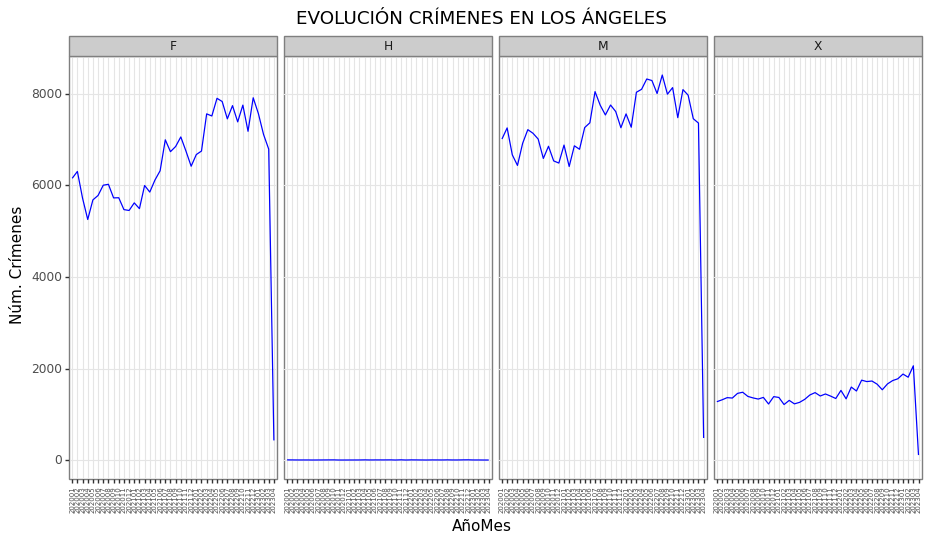

<ggplot: (367353853)>

In [9]:
p1 = (
      ggplot(to_gr, aes(x = "yearmoncat", y = "n"))
    + geom_line(group = 1, color ="blue")
    + labs(
     title = "EVOLUCIÓN CRÍMENES EN LOS ÁNGELES",
     x = "AñoMes",
     y = "Núm. Crímenes"
    )
    + facet_grid(".~vict_sex")
    + theme_bw()
    + theme(
        panel_grid_minor=element_blank(),
        axis_text_x=element_text(angle = 90, hjust = 0.5, size = 5)
    )
)
p1

+ Del gráfico, podemos pulirle un poco más, eliminando el tipo "H" y filtrando por el año mes "202304" que apenas hay valores reportados todavía.
+ En cualquier caso, ya podemos ver una clara subida de los crímenes tanto en mujeres como en hombres, aunque con cierta estabilización durante el 2022.

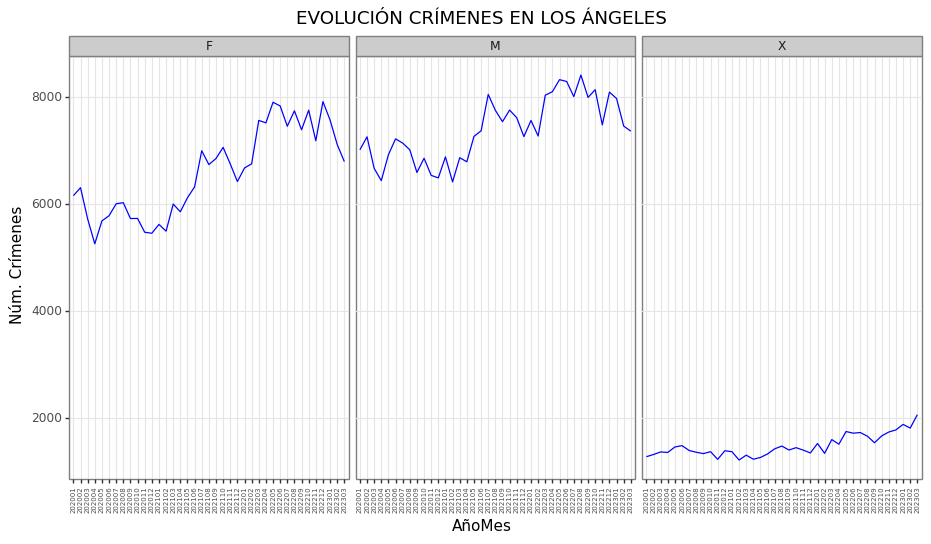

<ggplot: (367898736)>

In [10]:
to_gr = (
    to_gr
    >> filter(f.vict_sex != "H")
    >> filter(f.yearmon < 202304)
)

p1 = (
      ggplot(to_gr, aes(x = "yearmoncat", y = "n"))
    + geom_line(group = 1, color ="blue")
    + labs(
     title = "EVOLUCIÓN CRÍMENES EN LOS ÁNGELES",
     x = "AñoMes",
     y = "Núm. Crímenes"
    )
    + facet_grid(".~vict_sex")
    + theme_bw()
    + theme(
        panel_grid_minor=element_blank(),
        axis_text_x=element_text(angle = 90, hjust = 0.5, size = 5)
    )
)
p1

+ Podemos en este caso, al tratarse de solamente tres series, representarlas todas sobre el mismo gráfico con diferentes colores.
+ Y añadir un ajuste de tipo "smooth" para entender un poco mejor la evolución de los crímentes en el tiempo.

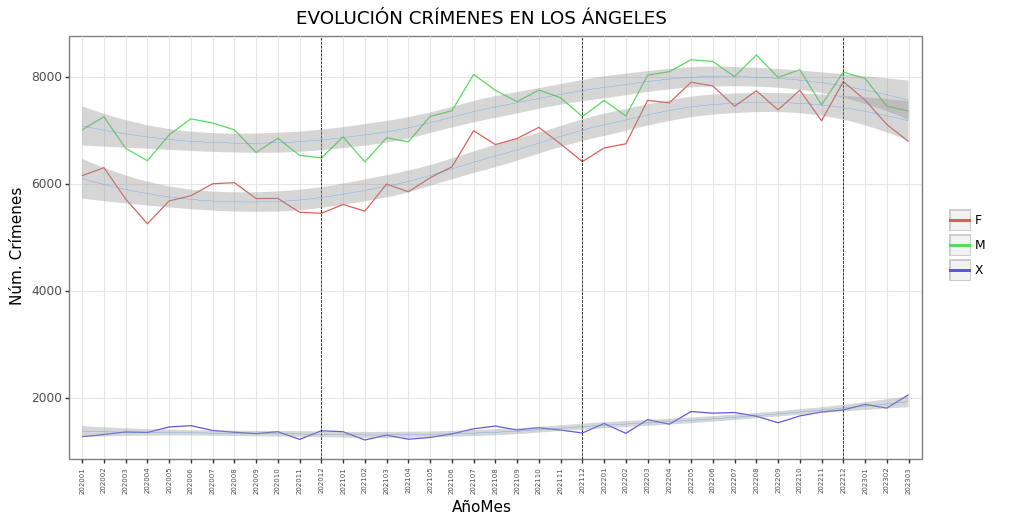

<ggplot: (367308788)>

In [11]:
p1 = (
      ggplot(to_gr, aes(x = "yearmoncat", y = "n", group = "vict_sex"))
    + geom_line(aes(color = "vict_sex"))
    + labs(
     title = "EVOLUCIÓN CRÍMENES EN LOS ÁNGELES",
     x = "AñoMes",
     y = "Núm. Crímenes"
    )
    + geom_vline(xintercept = 12, linetype = 'dashed', size = 0.3)
    + geom_vline(xintercept = 24, linetype = 'dashed', size = 0.3)
    + geom_vline(xintercept = 36, linetype = 'dashed', size = 0.3)
    + geom_smooth(colour="dodgerblue", size = 0.1)
    + theme_bw()
    + theme(
        panel_grid_minor=element_blank(),
        axis_text_x=element_text(angle = 90, hjust = 0.5, size = 5),
        legend_title = element_blank()
    )
)
p1

---

+ Volvemos al conjunto de datos y vamos a seleccionar las variables que pueden tener interés.
+ Estudiaremos diferentes variables para ver los niveles disponibles.
+ Definiremos la variable objetivo para hacer el modelo.
+ De cada variable iremos comentando lo que queremos hacer para luego ejecutar todos los cambios de forma conjunta.

In [12]:
head(datcrime, n  = 5)

,dr_no,fecha_hora,mes,semana,hora,dia,anio,yearmon,date_rptd,date_occ,time_occ,area,area_name,rpt_dist_no,part_1_2,crm_cd,crm_cd_desc,mocodes,vict_age,vict_sex,vict_descent,premis_cd,premis_desc,weapon_used_cd,weapon_desc,status,status_desc,crm_cd_1,crm_cd_2,crm_cd_3,crm_cd_4,location,cross_street,lat,lon
,<int32>,<datetime64[ns]>,<int64>,<UInt32>,<int64>,<object>,<int64>,<int64>,<object>,<object>,<int32>,<int32>,<object>,<int32>,<int32>,<int32>,<object>,<object>,<int32>,<object>,<object>,<float64>,<object>,<float64>,<object>,<object>,<object>,<float64>,<float64>,<float64>,<float64>,<object>,<object>,<float64>,<float64>
0,10304468,2020-01-08 12:00:00,1,2,12,Wednesday,2020,202001,01/08/2020 12:00:00 AM,01/08/2020 12:00:00 AM,2230,3,Southwest,377,2,624,BATTERY - SIMPLE ASSAULT,0444 0913,36,F,B,501.0,SINGLE FAMILY DWELLING,400.0,"STRONG-ARM (HANDS, FIST, FEET OR BODILY FORCE)",AO,Adult Other,624.0,NaN,NaN,NaN,1100 W 39TH PL,,34.0141,-118.2978
1,190101086,2020-01-02 12:00:00,1,1,12,Thursday,2020,202001,01/02/2020 12:00:00 AM,01/01/2020 12:00:00 AM,330,1,Central,163,2,624,BATTERY - SIMPLE ASSAULT,0416 1822 1414,25,M,H,102.0,SIDEWALK,500.0,UNKNOWN WEAPON/OTHER WEAPON,IC,Invest Cont,624.0,NaN,NaN,NaN,700 S HILL ST,,34.0459,-118.2545
2,200110444,2020-04-14 12:00:00,4,16,12,Tuesday,2020,202004,04/14/2020 12:00:00 AM,02/13/2020 12:00:00 AM,1200,1,Central,155,2,845,SEX OFFENDER REGISTRANT OUT OF COMPLIANCE,1501,0,X,X,726.0,POLICE FACILITY,NaN,,AA,Adult Arrest,845.0,NaN,NaN,NaN,200 E 6TH ST,,34.0448,-118.2474
3,191501505,2020-01-01 12:00:00,1,1,12,Wednesday,2020,202001,01/01/2020 12:00:00 AM,01/01/2020 12:00:00 AM,1730,15,N Hollywood,1543,2,745,VANDALISM - MISDEAMEANOR ($399 OR UNDER),0329 1402,76,F,W,502.0,"MULTI-UNIT DWELLING (APARTMENT, DUPLEX, ETC)",NaN,,IC,Invest Cont,745.0,998.0,NaN,NaN,5400 CORTEEN PL,,34.1685,-118.4019
4,191921269,2020-01-01 12:00:00,1,1,12,Wednesday,2020,202001,01/01/2020 12:00:00 AM,01/01/2020 12:00:00 AM,415,19,Mission,1998,2,740,"VANDALISM - FELONY ($400 & OVER, ALL CHURCH VA...",0329,31,X,X,409.0,BEAUTY SUPPLY STORE,NaN,,IC,Invest Cont,740.0,NaN,NaN,NaN,14400 TITUS ST,,34.2198,-118.4468


In [13]:
datcrime.describe()

,dr_no,mes,semana,hora,anio,yearmon,time_occ,area,rpt_dist_no,part_1_2,crm_cd,vict_age,premis_cd,weapon_used_cd,crm_cd_1,crm_cd_2,crm_cd_3,crm_cd_4,lat,lon
,<float64>,<float64>,<Float64>,<float64>,<float64>,<float64>,<float64>,<float64>,<float64>,<float64>,<float64>,<float64>,<float64>,<float64>,<float64>,<float64>,<float64>,<float64>,<float64>,<float64>
count,6.949150e+05,694915.000000,694915.0,694915.0,694915.000000,694915.000000,694915.000000,694915.000000,694915.000000,694915.000000,694915.000000,694915.000000,694907.000000,241434.000000,694906.000000,51816.000000,1747.000000,52.000000,694915.000000,694915.000000
mean,2.134252e+08,6.192618,25.212855,12.0,2021.230415,202129.234141,1333.809936,10.712713,1117.650033,1.415976,500.592415,29.969890,305.024871,362.202080,500.332790,956.742782,982.900401,990.615385,33.962489,-117.968027
std,9.519111e+06,3.519034,15.366021,0.0,0.949421,94.308826,654.271226,6.089274,608.929482,0.492890,207.846384,21.689495,216.431529,123.804416,207.636381,112.844364,57.146206,29.227407,1.945728,6.748226
min,8.170000e+02,1.000000,1.0,12.0,2020.000000,202001.000000,1.000000,1.000000,101.000000,1.000000,110.000000,-2.000000,101.000000,101.000000,110.000000,121.000000,9.000000,821.000000,0.000000,-118.667600
25%,2.019173e+08,3.000000,11.0,12.0,2020.000000,202011.000000,900.000000,6.000000,622.000000,1.000000,330.000000,12.000000,101.000000,308.000000,330.000000,998.000000,998.000000,998.000000,34.013200,-118.429400
50%,2.116044e+08,6.000000,25.0,12.0,2021.000000,202110.000000,1413.000000,11.000000,1141.000000,1.000000,442.000000,31.000000,203.000000,400.000000,442.000000,998.000000,998.000000,998.000000,34.058400,-118.321400
75%,2.211135e+08,9.000000,39.0,12.0,2022.000000,202207.000000,1900.000000,16.000000,1617.000000,2.000000,626.000000,45.000000,501.000000,400.000000,626.000000,998.000000,998.000000,998.000000,34.163100,-118.273900
max,2.399097e+08,12.000000,53.0,12.0,2023.000000,202304.000000,2359.000000,21.000000,2199.000000,2.000000,956.000000,120.000000,971.000000,516.000000,956.000000,999.000000,999.000000,999.000000,34.334300,0.000000


+ Para el EDA vamos a utilizar "autoviz" que genera un informe completo de todo el dataset.
+ https://pypi.org/project/autoviz/

In [14]:
from autoviz import data_cleaning_suggestions
data_cleaning_suggestions(datcrime)

Imported v0.1.58. After importing, execute '%matplotlib inline' to display charts in Jupyter.
    AV = AutoViz_Class()
    dfte = AV.AutoViz(filename, sep=',', depVar='', dfte=None, header=0, verbose=1, lowess=False,
               chart_format='svg',max_rows_analyzed=150000,max_cols_analyzed=30, save_plot_dir=None)
Update: verbose=0 displays charts in your local Jupyter notebook.
        verbose=1 additionally provides EDA data cleaning suggestions. It also displays charts.
        verbose=2 does not display charts but saves them in AutoViz_Plots folder in local machine.
        chart_format='bokeh' displays charts in your local Jupyter notebook.
        chart_format='server' displays charts in your browser: one tab for each chart type
        chart_format='html' silently saves interactive HTML files in your local machine
Data cleaning improvement suggestions. Complete them before proceeding to ML modeling.


,Nuniques,dtype,Nulls,Nullpercent,NuniquePercent,Value counts Min,Data cleaning improvement suggestions
dr_no,694915,int32,0,0.000000,100.000000,0,possible ID column: drop
mocodes,236904,object,0,0.000000,34.091076,1,combine rare categories
location,61425,object,0,0.000000,8.839211,1,combine rare categories
cross_street,9139,object,0,0.000000,1.315125,1,combine rare categories
lat,5380,float64,0,0.000000,0.774195,0,highly skewed: drop outliers or do box-cox transform
lon,4960,float64,0,0.000000,0.713756,0,highly skewed: drop outliers or do box-cox transform
time_occ,1439,int32,0,0.000000,0.207076,0,
rpt_dist_no,1194,int32,0,0.000000,0.171820,0,
fecha_hora,1189,datetime64[ns],0,0.000000,0.171100,0,
date_rptd,1189,object,0,0.000000,0.171100,349,


+ El informe ya nos indica que las variables "crm_cd_*" las podemos eliminar por el alto valor de NAs.
+ También la variable por ser equivalente a un "id" como "dr_no" también se puede eliminar.
+ E igualmente "mocodes".

In [15]:
#--- Variable area_name
datcrime >> count(f.area_name, sort = True) >> ungroup(f.area_name)

,area_name,n
,<object>,<int64>
0,Central,46434
1,77th Street,44051
2,Pacific,40013
3,Southwest,39022
4,Hollywood,37340
5,Southeast,35730
6,Olympic,34832
7,N Hollywood,34714
8,Newton,34557


In [16]:
#--- Variable crm_cd_desc filtro casos que tengan más de 1000 crímenes.
datcrime >> count(f.crm_cd_desc, sort = True) >> ungroup(f.crm_cd_desc) >> filter(f.n > 1000)

,crm_cd_desc,n
,<object>,<int64>
0,VEHICLE - STOLEN,74786
1,BATTERY - SIMPLE ASSAULT,54765
2,THEFT OF IDENTITY,45302
3,BURGLARY FROM VEHICLE,43531
4,"VANDALISM - FELONY ($400 & OVER, ALL CHURCH VANDALISMS)",42826
5,BURGLARY,42378
6,"ASSAULT WITH DEADLY WEAPON, AGGRAVATED ASSAULT",39955
7,THEFT PLAIN - PETTY ($950 & UNDER),35658
8,INTIMATE PARTNER - SIMPLE ASSAULT,35211


+ En esta variable vemos que hay casos muy minoritarios, que vamos a agruparles en unas categorías mayores (proceso de "lumping")
+ Nos vamos a quedar con los tipos de crímenes que hayan tenido más de 1000 casos.

In [17]:
#--- Variable status_desc
datcrime >> count(f.status_desc, sort = True) >> ungroup(f.status_desc)

,status_desc,n
,<object>,<int64>
0,Invest Cont,555684
1,Adult Other,75372
2,Adult Arrest,60584
3,Juv Arrest,2148
4,Juv Other,1124
5,UNK,3


+ Esta va a ser nuestra variable "target". Definiremos "Invest Cont" como "Open" (caso abierto) y el resto como caso "Closed".

In [18]:
#--- Ahora la variable weapon_desc
datcrime >> count(f.weapon_desc, sort = True) >> ungroup(f.weapon_desc) >> filter(f.n >= 1000)

,weapon_desc,n
,<object>,<int64>
0,,453481
1,"STRONG-ARM (HANDS, FIST, FEET OR BODILY FORCE)",129668
2,UNKNOWN WEAPON/OTHER WEAPON,24820
3,VERBAL THREAT,17754
4,HAND GUN,14962
5,SEMI-AUTOMATIC PISTOL,5550
6,KNIFE WITH BLADE 6INCHES OR LESS,5030
7,UNKNOWN FIREARM,4944
8,OTHER KNIFE,4390


+ En este caso, vamos también a quedarnos con los casos que tengan más de 1000 ocurrencias.
+ Son 21 casos y muchos de ellos están en blanco, los tendremos que codificar a NA.

In [19]:
#--- Ahora la variable cross_street 
datcrime >> count(f.cross_street, sort = True) >> ungroup(f.cross_street) >> filter(f.n >= 1000)

,cross_street,n
,<object>,<int64>
0,,582058
1,BROADWAY,1841
2,FIGUEROA ST,1404
3,VERMONT AV,1185
4,FIGUEROA,1167
5,WESTERN AV,1110
6,SAN PEDRO,1072
7,MAIN ST,1069


+ En esta variable hay muchos elementos en blanco (582k). Un número muy limitado tiene valores.
+ Es una variable de la que podemos prescindir.

In [20]:
#--- Ahora la variable location 
datcrime >> count(f.location, sort = True) >> ungroup(f.location) >> filter(f.n >= 500)

,location,n
,<object>,<int64>
0,800 N ALAMEDA ST,1264
1,7TH,1166
2,6TH ST,1143
3,7TH ST,1108
4,6TH,1085
5,10200 SANTA MONICA BL,982
6,FIGUEROA ST,926
7,5TH,904
8,100 THE GROVE DR,875


+ Es una variable que tiene múltiples niveles. No incluye valores "NA". 
+ Es otra variable en principio que se puede prescindir.

In [21]:
#--- Ahora la variable mocodes
datcrime >> count(f.mocodes, sort = True) >> ungroup(f.mocodes) >> filter(f.n >= 500)

,mocodes,n
,<object>,<int64>
0,,95563
1,0344,28507
2,0329,16088
3,1822 0344,7929
...,...,...
4,1501,6925
84,2000 0416,515
85,0400 0416 1822,513
86,0443,506


+ De las 600, filas, vemos que salvo unos cuantos mocodes, el resto tienen frecuencias pequeñas.
+ Y de ellos 100k son valores NA. 
+ Es una variable de la que podemos prescindir de principio. 
+ Dependiendo del resultado del modelo, la incluiremos.

In [22]:
#--- Ahora la variable vict_descent
datcrime >> count(f.vict_descent, sort = True) >> ungroup(f.vict_descent) >> filter(f.n >= 500)

,vict_descent,n
,<object>,<int64>
0,H,213713
1,W,143158
2,B,100322
3,,91052
4,X,64399
5,O,54984
6,A,15125
7,K,3630
8,F,2853


+ Son las diferentes etnias.
+ Los blancos los codificamos como NAs.

In [23]:
#--- Ahora la variable hora
datcrime >> count(f.hora)

,hora,n
,<int64>,<int64>
0,12,694915


+ Aunque hemos añadido la nueva variable "hora", vemos que tiene solamente un único valor que es "12". Parece que los datos por defecto solo tienen en cuenta la fecha, pero no la hora minutos, segundos.
+ Eliminamos por tanto esta variable.

----

+ Aplicamos todo ese conjunto de cambios en un mismo proceso de transformación.
+ Mucho del proceso va a consistir en eliminar variables que no vemos que podamos obtener información.

In [24]:
datcrime_cl = (
    datcrime
    #- Los vacíos de weapon_desc son NA y luego hacemos lumping y convertimos en factor
    >> mutate( weapon_cl = if_else(f.weapon_desc == "", NA, f.weapon_desc))
    >> mutate( weapon_cl = fct_lump_n(f.weapon_cl, 1000)) 
    >> mutate( weapon_cl = as_factor(f.weapon_cl))
    #- definimos la target
    >> mutate( target = if_else(f.status_desc == "Invest Cont", "Open", "Closed"))
    >> mutate( target = as_factor(f.target))
    #- Hacemos lumping en crm_cd_desc como comentamos anteriormente.
    >> mutate( crmdesc = fct_lump_n(f.crm_cd_desc, 1000))
    >> mutate( crmdesc = as_factor(f.crmdesc))
    >> relocate(f.crmdesc, _before = f.target)
    #- Codificamos los NAs en vict_descent
    >> mutate( victdesc = if_else(f.vict_descent == "", NA, f.vict_descent))
    >> mutate( victdesc = as_factor(f.victdesc))
    >> relocate( f.victdesc , _before = f.target)
)
head(datcrime_cl)

,dr_no,fecha_hora,mes,semana,hora,dia,anio,yearmon,date_rptd,date_occ,time_occ,area,area_name,rpt_dist_no,part_1_2,crm_cd,crm_cd_desc,mocodes,vict_age,vict_sex,vict_descent,premis_cd,premis_desc,weapon_used_cd,weapon_desc,status,status_desc,crm_cd_1,crm_cd_2,crm_cd_3,crm_cd_4,location,cross_street,lat,lon,weapon_cl,crmdesc,victdesc,target
,<int32>,<datetime64[ns]>,<int64>,<UInt32>,<int64>,<object>,<int64>,<int64>,<object>,<object>,<int32>,<int32>,<object>,<int32>,<int32>,<int32>,<object>,<object>,<int32>,<object>,<object>,<float64>,<object>,<float64>,<object>,<object>,<object>,<float64>,<float64>,<float64>,<float64>,<object>,<object>,<float64>,<float64>,<category>,<category>,<category>,<category>
0,10304468,2020-01-08 12:00:00,1,2,12,Wednesday,2020,202001,01/08/2020 12:00:00 AM,01/08/2020 12:00:00 AM,2230,3,Southwest,377,2,624,BATTERY - SIMPLE ASSAULT,0444 0913,36,F,B,501.0,SINGLE FAMILY DWELLING,400.0,"STRONG-ARM (HANDS, FIST, FEET OR BODILY FORCE)",AO,Adult Other,624.0,NaN,NaN,NaN,1100 W 39TH PL,,34.0141,-118.2978,"STRONG-ARM (HANDS, FIST, FEET OR BODILY FORCE)",BATTERY - SIMPLE ASSAULT,B,Closed
1,190101086,2020-01-02 12:00:00,1,1,12,Thursday,2020,202001,01/02/2020 12:00:00 AM,01/01/2020 12:00:00 AM,330,1,Central,163,2,624,BATTERY - SIMPLE ASSAULT,0416 1822 1414,25,M,H,102.0,SIDEWALK,500.0,UNKNOWN WEAPON/OTHER WEAPON,IC,Invest Cont,624.0,NaN,NaN,NaN,700 S HILL ST,,34.0459,-118.2545,UNKNOWN WEAPON/OTHER WEAPON,BATTERY - SIMPLE ASSAULT,H,Open
2,200110444,2020-04-14 12:00:00,4,16,12,Tuesday,2020,202004,04/14/2020 12:00:00 AM,02/13/2020 12:00:00 AM,1200,1,Central,155,2,845,SEX OFFENDER REGISTRANT OUT OF COMPLIANCE,1501,0,X,X,726.0,POLICE FACILITY,NaN,,AA,Adult Arrest,845.0,NaN,NaN,NaN,200 E 6TH ST,,34.0448,-118.2474,NaN,SEX OFFENDER REGISTRANT OUT OF COMPLIANCE,X,Closed
3,191501505,2020-01-01 12:00:00,1,1,12,Wednesday,2020,202001,01/01/2020 12:00:00 AM,01/01/2020 12:00:00 AM,1730,15,N Hollywood,1543,2,745,VANDALISM - MISDEAMEANOR ($399 OR UNDER),0329 1402,76,F,W,502.0,"MULTI-UNIT DWELLING (APARTMENT, DUPLEX, ETC)",NaN,,IC,Invest Cont,745.0,998.0,NaN,NaN,5400 CORTEEN PL,,34.1685,-118.4019,NaN,VANDALISM - MISDEAMEANOR ($399 OR UNDER),W,Open
4,191921269,2020-01-01 12:00:00,1,1,12,Wednesday,2020,202001,01/01/2020 12:00:00 AM,01/01/2020 12:00:00 AM,415,19,Mission,1998,2,740,"VANDALISM - FELONY ($400 & OVER, ALL CHURCH VANDALISMS)",0329,31,X,X,409.0,BEAUTY SUPPLY STORE,NaN,,IC,Invest Cont,740.0,NaN,NaN,NaN,14400 TITUS ST,,34.2198,-118.4468,NaN,"VANDALISM - FELONY ($400 & OVER, ALL CHURCH VANDALISMS)",X,Open
5,200100501,2020-01-02 12:00:00,1,1,12,Thursday,2020,202001,01/02/2020 12:00:00 AM,01/01/2020 12:00:00 AM,30,1,Central,163,1,121,"RAPE, FORCIBLE",0413 1822 1262 1415,25,F,H,735.0,NIGHT CLUB (OPEN EVENINGS ONLY),500.0,UNKNOWN WEAPON/OTHER WEAPON,IC,Invest Cont,121.0,998.0,NaN,NaN,700 S BROADWAY,,34.0452,-118.2534,UNKNOWN WEAPON/OTHER WEAPON,"RAPE, FORCIBLE",H,Open


In [25]:
#-- Separo el proceso en dos partes. Todo junto no termina de completarse.
#-- En esta parte elimino variables que no voy a usar.
datcrime_cl = (
    datcrime_cl
    #- Eliminamos muchas variables que vemos que tienen muchos NAs. Otras que hemos hecho limping.
    >> select( ~f.crm_cd, ~f.crm_cd_1, ~f.crm_cd_2, ~f.crm_cd_3, ~f.crm_cd_4, ~f.dr_no, ~f.date_rptd)
    >> select( ~f.date_occ, ~f.time_occ, ~f.premis_desc, ~f.weapon_used_cd, ~f.weapon_desc)
    >> select( ~f.status, ~f.crm_cd_desc, ~f.premis_cd)
    >> select( ~f.part_1_2, ~f.rpt_dist_no)
    >> select( ~f.status_desc, ~f.cross_street)
    #- area esta repetida con area_name
    >> select( ~f.area)
    #- Eliminamos la fecha, el año y el añomes son variables que para nuevos casos no podremos repetir
    #- No eliminamos por ahora yearmon porque vamos a utilizarla para separar el conjunto de train y de test
    >> select( ~f.fecha_hora, ~f.anio)
    #- Eliminamos la variable location por lo comentado por el alto número de niveles.
    >> select( ~f.location, ~f.mocodes, ~f.vict_descent)
    #- Eliminamos la variable hora
    >> select( ~f.hora)
)
head(datcrime_cl)

,mes,semana,dia,yearmon,area_name,vict_age,vict_sex,lat,lon,weapon_cl,crmdesc,victdesc,target
,<int64>,<UInt32>,<object>,<int64>,<object>,<int32>,<object>,<float64>,<float64>,<category>,<category>,<category>,<category>
0,1,2,Wednesday,202001,Southwest,36,F,34.0141,-118.2978,"STRONG-ARM (HANDS, FIST, FEET OR BODILY FORCE)",BATTERY - SIMPLE ASSAULT,B,Closed
1,1,1,Thursday,202001,Central,25,M,34.0459,-118.2545,UNKNOWN WEAPON/OTHER WEAPON,BATTERY - SIMPLE ASSAULT,H,Open
2,4,16,Tuesday,202004,Central,0,X,34.0448,-118.2474,NaN,SEX OFFENDER REGISTRANT OUT OF COMPLIANCE,X,Closed
3,1,1,Wednesday,202001,N Hollywood,76,F,34.1685,-118.4019,NaN,VANDALISM - MISDEAMEANOR ($399 OR UNDER),W,Open
4,1,1,Wednesday,202001,Mission,31,X,34.2198,-118.4468,NaN,"VANDALISM - FELONY ($400 & OVER, ALL CHURCH VANDALISMS)",X,Open
5,1,1,Thursday,202001,Central,25,F,34.0452,-118.2534,UNKNOWN WEAPON/OTHER WEAPON,"RAPE, FORCIBLE",H,Open


+ Con la longitud y latitud, vamos a crear una variable que es la distancia euclídea (una aproximación sin tener en cuenta la distancia geodéisca)
+ Otra variable que podemos crear es una que agrupen las horas.

In [26]:
datcrime_cl = (
    datcrime_cl 
    >> mutate( dist_lonlat = sqrt(f.lat**2 + f.lon**2))
    >> relocate( f.dist_lonlat, _before = f.target)
)
head(datcrime_cl, n = 10)

,mes,semana,dia,yearmon,area_name,vict_age,vict_sex,lat,lon,weapon_cl,crmdesc,victdesc,dist_lonlat,target
,<int64>,<UInt32>,<object>,<int64>,<object>,<int32>,<object>,<float64>,<float64>,<category>,<category>,<category>,<float64>,<category>
0,1,2,Wednesday,202001,Southwest,36,F,34.0141,-118.2978,"STRONG-ARM (HANDS, FIST, FEET OR BODILY FORCE)",BATTERY - SIMPLE ASSAULT,B,123.090733,Closed
1,1,1,Thursday,202001,Central,25,M,34.0459,-118.2545,UNKNOWN WEAPON/OTHER WEAPON,BATTERY - SIMPLE ASSAULT,H,123.057914,Open
2,4,16,Tuesday,202004,Central,0,X,34.0448,-118.2474,NaN,SEX OFFENDER REGISTRANT OUT OF COMPLIANCE,X,123.050786,Closed
3,1,1,Wednesday,202001,N Hollywood,76,F,34.1685,-118.4019,NaN,VANDALISM - MISDEAMEANOR ($399 OR UNDER),W,123.233503,Open
4,1,1,Wednesday,202001,Mission,31,X,34.2198,-118.4468,NaN,"VANDALISM - FELONY ($400 & OVER, ALL CHURCH VANDALISMS)",X,123.290872,Open
5,1,1,Thursday,202001,Central,25,F,34.0452,-118.2534,UNKNOWN WEAPON/OTHER WEAPON,"RAPE, FORCIBLE",H,123.056663,Open
6,1,1,Thursday,202001,Central,23,M,34.0483,-118.2631,NaN,SHOPLIFTING - PETTY THEFT ($950 & UNDER),H,123.066842,Open
7,1,1,Saturday,202001,Central,0,X,34.0448,-118.2474,NaN,OTHER MISCELLANEOUS CRIME,X,123.050786,Open
8,1,1,Saturday,202001,Central,23,M,34.0677,-118.2398,NaN,"THEFT-GRAND ($950.01 & OVER)EXCPT,GUNS,FOWL,LIVESTK,PROD",B,123.049821,Open


+ Ahora ya podemos modelizar....

---
---

## Modelo

+ Lo que vamos a hacer es usar H2O y usaremos "AutoML".
+ Crearemos múltiples modelos de forma automática. 
+ De esta forma nos escogerá el mejor modelo de un conjunto variado, incluyendo cierta hiperparametrización.

In [27]:
#- Importamos librería y arrancamos el cluster de h2o.
import h2o
from h2o.automl import H2OAutoML
h2o.init()
h2o.no_progress()

Checking whether there is an H2O instance running at http://localhost:54321..... not found.
Attempting to start a local H2O server...
  Java Version: openjdk version "19.0.2" 2023-01-17; OpenJDK Runtime Environment Homebrew (build 19.0.2); OpenJDK 64-Bit Server VM Homebrew (build 19.0.2, mixed mode, sharing)
  Starting server from /Users/carlosortega/opt/miniconda3/envs/cofml/lib/python3.9/site-packages/h2o/backend/bin/h2o.jar
  Ice root: /var/folders/j9/m6xn7ss56bzb7x46wbc56yfm0000gn/T/tmpfmn0q9ps
  JVM stdout: /var/folders/j9/m6xn7ss56bzb7x46wbc56yfm0000gn/T/tmpfmn0q9ps/h2o_carlosortega_started_from_python.out
  JVM stderr: /var/folders/j9/m6xn7ss56bzb7x46wbc56yfm0000gn/T/tmpfmn0q9ps/h2o_carlosortega_started_from_python.err
  Server is running at http://127.0.0.1:54321
Connecting to H2O server at http://127.0.0.1:54321 ... successful.


H2O_cluster_uptime:,03 secs
H2O_cluster_timezone:,Europe/Madrid
H2O_data_parsing_timezone:,UTC
H2O_cluster_version:,3.40.0.3
H2O_cluster_version_age:,6 days
H2O_cluster_name:,H2O_from_python_carlosortega_71hfe8
H2O_cluster_total_nodes:,1
H2O_cluster_free_memory:,4 Gb
H2O_cluster_total_cores:,8
H2O_cluster_allowed_cores:,8
H2O_cluster_status:,"locked, healthy"


+ Antes de convertir el dataframe con los crímenes a un objeto h2o vamos a separar los dos conjuntos de train y test en función de la fecha "yearmon".
    + Usaremos los datos desde 2022-Octubre hasta la actualidad como datos de test, y el resto para entrenar.
    + Esta separación es equivalente a utilizar un 80% - 20%.

In [28]:
#- Antes de convertir el dataframe con los crímenes a un objeto h2o vamos a separar los dos conjuntos de train y test en función de la fecha "yearmon".
train = (
    datcrime_cl
    >> filter(f.yearmon >= 202210)
    >> select(~f.yearmon) 
)
test = (
    datcrime_cl
    >> filter(f.yearmon < 202210)
    >> select(~f.yearmon)
)

train_h2o = h2o.H2OFrame(train)
test_h2o = h2o.H2OFrame(test)


In [29]:
#- Variable Objetivo
y = "target"

#- Excluímos algoritmos de DeepLearning y Stacked.
#- Ejecutamos el AutoML durante 2 minutos.
exclude_algos = ['DeepLearning', 'StackedEnsemble']
aml = H2OAutoML(
                max_runtime_secs = 120, 
                exclude_algos = exclude_algos,
                seed=1
              )

#- Entrenamiento
aml.train( 
          y=y, 
          training_frame = train_h2o
         )


Model Details
=============
H2OGradientBoostingEstimator : Gradient Boosting Machine
Model Key: GBM_1_AutoML_1_20230411_05002


Model Summary: 
    number_of_trees    number_of_internal_trees    model_size_in_bytes    min_depth    max_depth    mean_depth    min_leaves    max_leaves    mean_leaves
--  -----------------  --------------------------  ---------------------  -----------  -----------  ------------  ------------  ------------  -------------
    42                 42                          330293                 15           15           15            313           674           520.643

ModelMetricsBinomial: gbm
** Reported on train data. **

MSE: 0.06696610112814523
RMSE: 0.2587780924424346
LogLoss: 0.22227090393496585
Mean Per-Class Error: 0.28913054452352194
AUC: 0.9238643638155508
AUCPR: 0.9881512372362415
Gini: 0.8477287276311016

Confusion Matrix (Act/Pred) for max f1 @ threshold = 0.5683572099020449
        Closed    Open    Error    Rate
------  --------  ------  -------  ------------------
Closed  6535      8119    0.554    (8119.0/14654.0)
Open    2499      100704  0.0242   (2499.0/103203.0)
Total   9034      108823  0.0901   (10618.0/117857.0)

Maximum Metrics: Maximum metrics at their respective thresholds
metric                       threshold    value     idx
---------------------------  -----------  --------  -----
max f1                       0.568357     0.949921  265
max f2                       0.35354      0.974221  338
max f0point5                 0.758131     0.948559  183
max accuracy                 0.575096     0.909967  262
max precision                0.995715     1         0
max recall                   0.160815     1         388
max specificity              0.995715     1         0
max absolute_mcc             0.70956      0.561072  206
max min_per_class_accuracy   0.836486     0.841574  141
max mean_per_class_accuracy  0.8658       0.843761  124
max tns                      0.995715     14654     0
max fns                      0.995715     102642    0
max fps                      0.069919     14654     399
max tps                      0.160815     103203    388
max tnr                      0.995715     1         0
max fnr                      0.995715     0.994564  0
max fpr                      0.069919     1         399
max tpr                      0.160815     1         388

Gains/Lift Table: Avg response rate: 87,57 %, avg score: 87,54 %
group    cumulative_data_fraction    lower_threshold    lift      cumulative_lift    response_rate    score     cumulative_response_rate    cumulative_score    capture_rate    cumulative_capture_rate    gain      cumulative_gain    kolmogorov_smirnov
-------  --------------------------  -----------------  --------  -----------------  ---------------  --------  --------------------------  ------------------  --------------  -------------------------  --------  -----------------  --------------------
1        0.0100036                   0.99502            1.14199   1.14199            1                0.995477  1                           0.995477            0.0114241       0.0114241                  14.1992   14.1992            0.0114241
2        0.0200073                   0.994555           1.14199   1.14199            1                0.994765  1                           0.995121            0.0114241       0.0228482                  14.1992   14.1992            0.0228482
3        0.0300025                   0.994211           1.14199   1.14199            1                0.994379  1                           0.994874            0.0114144       0.0342626                  14.1992   14.1992            0.0342626
4        0.0400061                   0.993877           1.14199   1.14199            1                0.994039  1                           0.994665            0.0114241       0.0456867                  14.1992   14.1992            0.0456867
5        0.0500013                   0.993572           1.14199   1.14199            1                0

In [30]:
h2o.automl.get_leaderboard(aml)

model_id,auc,logloss,aucpr,mean_per_class_error,rmse,mse
GBM_1_AutoML_1_20230411_05002,0.857109,0.272685,0.975022,0.407038,0.286907,0.0823154
XGBoost_1_AutoML_1_20230411_05002,0.849296,0.278429,0.973581,0.412344,0.290279,0.0842621
GLM_1_AutoML_1_20230411_05002,0.835534,0.287684,0.970836,0.435764,0.29518,0.087131
GBM_3_AutoML_1_20230411_05002,0.833634,0.354504,0.969361,0.432781,0.322161,0.103788
GBM_2_AutoML_1_20230411_05002,0.828093,0.347844,0.965801,0.443622,0.319303,0.101954
XGBoost_2_AutoML_1_20230411_05002,0.755757,0.475202,0.95023,0.443769,0.381981,0.145909
DRF_1_AutoML_1_20230411_05002,0.64517,4.56639,0.910053,0.5,0.382935,0.146639


In [31]:
# Visualization Libraries
import matplotlib.pyplot as plt
%matplotlib inline

+ En esta ejecución, obtenemos una lista de modelos de la que podemos extraer diferentes elementos:
    + Variables importantes.
    + Lista de variables importantes para cada modelo (para ver si éstas se repiten)
    + Correlación entre modelos.
    
<br>

+ Además de estos elementos, H2O ya incorpora un conjunto de funciones que nos permite estudiar la *interpretabilidad* del modelo.
    + Los valores SHAP de importancia de las variables (este elemento es muy importante para "Negocio").
    + En incluso para una fila determinada (un crimen en particular) ver cómo contribuye cada variable a que el mejore o empeore el modelo.

In [32]:
best_model = aml.get_best_model()
print(best_model)


Model Details
H2OGradientBoostingEstimator : Gradient Boosting Machine
Model Key: GBM_1_AutoML_1_20230411_05002


Model Summary: 
    number_of_trees    number_of_internal_trees    model_size_in_bytes    min_depth    max_depth    mean_depth    min_leaves    max_leaves    mean_leaves
--  -----------------  --------------------------  ---------------------  -----------  -----------  ------------  ------------  ------------  -------------
    42                 42                          330293                 15           15           15            313           674           520.643

ModelMetricsBinomial: gbm
** Reported on train data. **

MSE: 0.06696610112814523
RMSE: 0.2587780924424346
LogLoss: 0.22227090393496585
Mean Per-Class Error: 0.28913054452352194
AUC: 0.9238643638155508
AUCPR: 0.9881512372362415
Gini: 0.8477287276311016

Confusion Matrix (Act/Pred) for max f1 @ threshold = 0.5683572099020449
        Closed    Open    Error    Rate
------  --------  ------  -------  --------

In [33]:
best_model.model_performance(test_h2o)

ModelMetricsBinomial: gbm
** Reported on test data. **

MSE: 0.1534556477109823
RMSE: 0.39173415438404435
LogLoss: 0.5092602654058376
Mean Per-Class Error: 0.4309238579122357
AUC: 0.7659767926393662
AUCPR: 0.9198306720510685
Gini: 0.5319535852787325

Confusion Matrix (Act/Pred) for max f1 @ threshold = 0.492831741559763
        Closed    Open    Error    Rate
------  --------  ------  -------  -------------------
Closed  19860     104717  0.8406   (104717.0/124577.0)
Open    9623      442858  0.0213   (9623.0/452481.0)
Total   29483     547575  0.1981   (114340.0/577058.0)

Maximum Metrics: Maximum metrics at their respective thresholds
metric                       threshold    value     idx
---------------------------  -----------  --------  -----
max f1                       0.492832     0.885666  291
max f2                       0.198289     0.948062  377
max f0point5                 0.829759     0.855091  149
max accuracy                 0.56735      0.802923  264
max precision                0.995941     0.993687  0
max recall                   0.0693609    1         399
max specificity              0.995941     0.999799  0
max absolute_mcc             0.829759     0.328688  149
max min_per_class_accuracy   0.933493     0.682568  80
max mean_per_class_accuracy  0.947548     0.684782  66
max tns                      0.995941     124552    0
max fns                      0.995941     448546    0
max fps                      0.0693609    124577    399
max tps                      0.0693609    452481    399
max tnr                      0.995941     0.999799  0
max fnr                      0.995941     0.991304  0
max fpr                      0.0693609    1         399
max tpr                      0.0693609    1         399

Gains/Lift Table: Avg response rate: 78,41 %, avg score: 88,17 %
group    cumulative_data_fraction    lower_threshold    lift      cumulative_lift    response_rate    score     cumulative_response_rate    cumulative_score    capture_rate    cumulative_capture_rate    gain      cumulative_gain    kolmogorov_smirnov
-------  --------------------------  -----------------  --------  -----------------  ---------------  --------  --------------------------  ------------------  --------------  -------------------------  --------  -----------------  --------------------
1        0.0100007                   0.995502           1.26427   1.26427            0.991336         0.995971  0.991336                    0.995971            0.0126436       0.0126436                  26.427    26.427             0.0122423
2        0.0200015                   0.994862           1.26206   1.26317            0.989603         0.995175  0.99047                     0.995573            0.0126215       0.0252651                  26.2061   26.3166            0.0243822
3        0.0300005                   0.994305           1.25963   1.26199            0.987695         0.994576  0.989545                    0.995241            0.012595        0.0378602                  25.9627   26.1986            0.0364072
4        0.0400012                   0.993797           1.25455   1.26013            0.983712         0.994052  0.988086                    0.994944            0.0125464       0.0504065                  25.4547   26.0126            0.0481991
5        0.0500002                   0.993287           1.2583    1.25976            0.986655         0.993539  0.9878                      0.994663            0.0125817       0.0629883                  25.8301   25.9761            0.0601627
6        0.1                         0.990825           1.25097   1.25536            0.980903         0.992078  0.984352                    0.99337             0.0625485       0.125537                   25.0965   25.5363            0.118288
7        0.150001                    0.988023           1.23757   1.24943            0.970402         0.989447  0.979702                    0.992063            0.0618788       0.187416                   23.7573   24.9433      

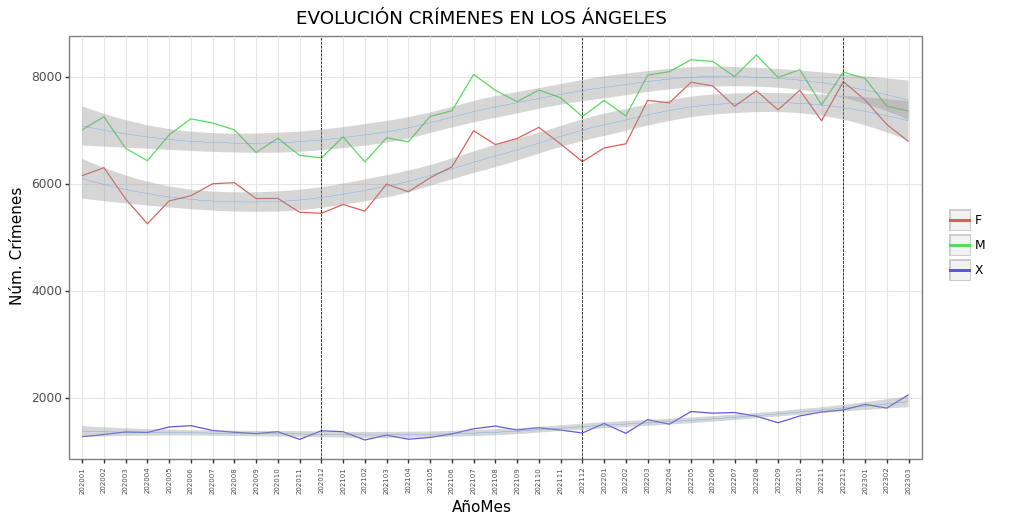

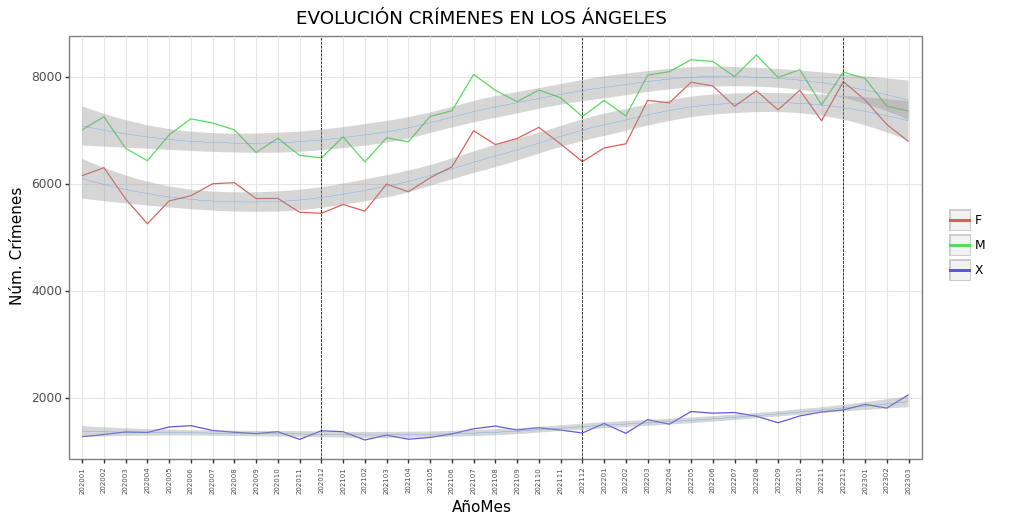

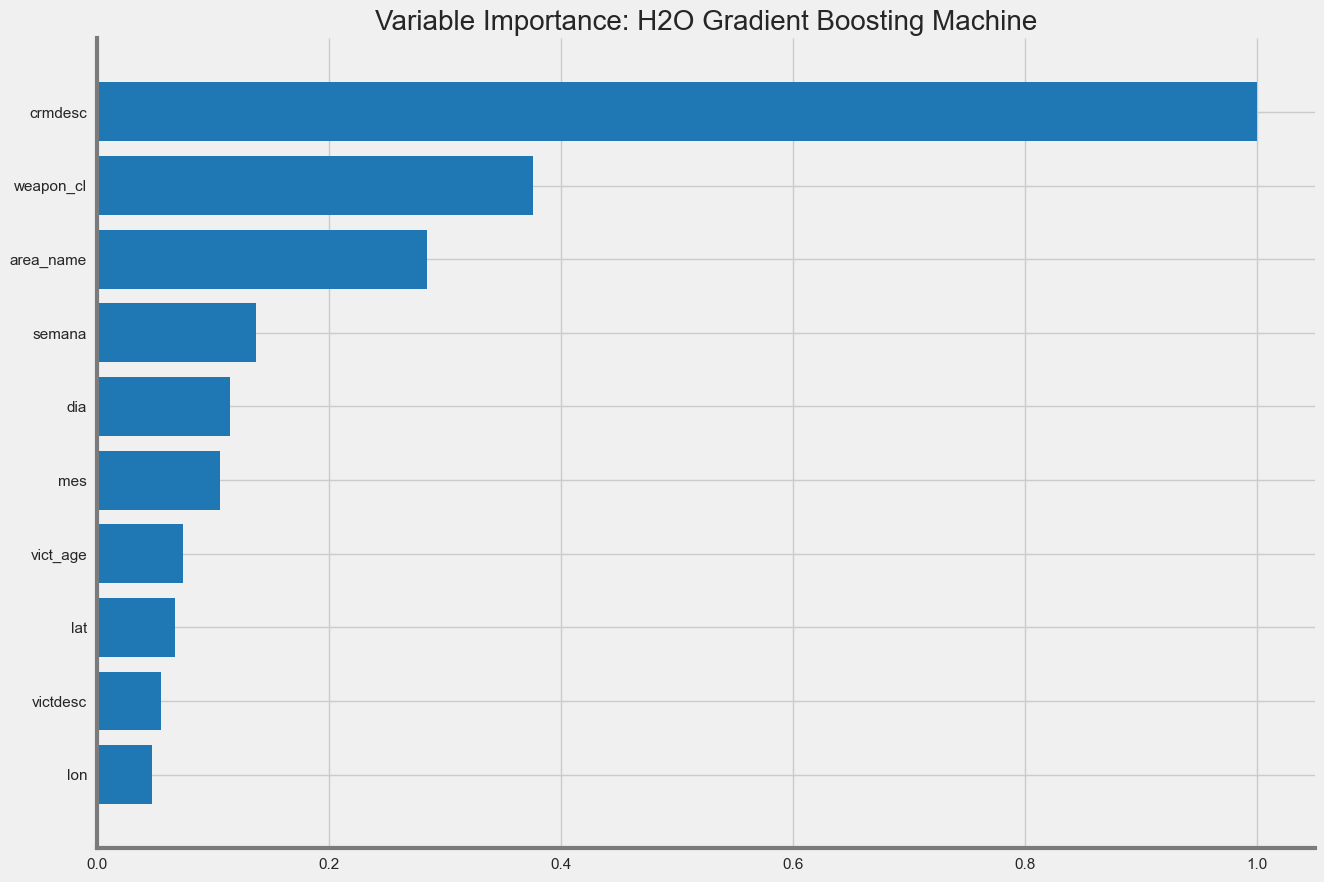

<Figure size 800x550 with 0 Axes>

In [34]:
best_model.varimp_plot()

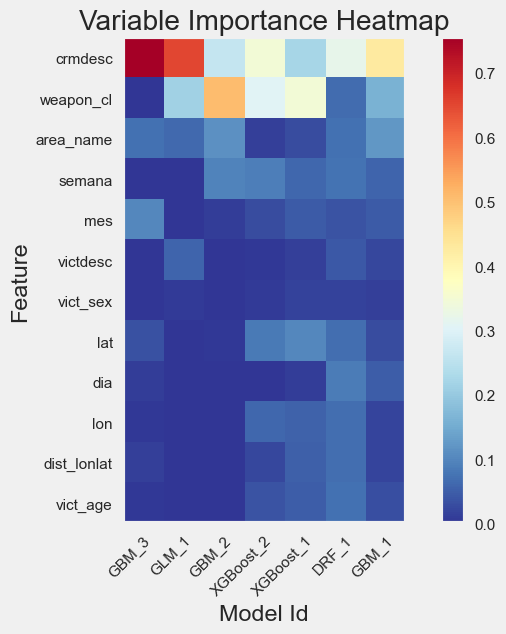

In [35]:
va_plot = aml.varimp_heatmap( figsize = (8,6))
va_plot

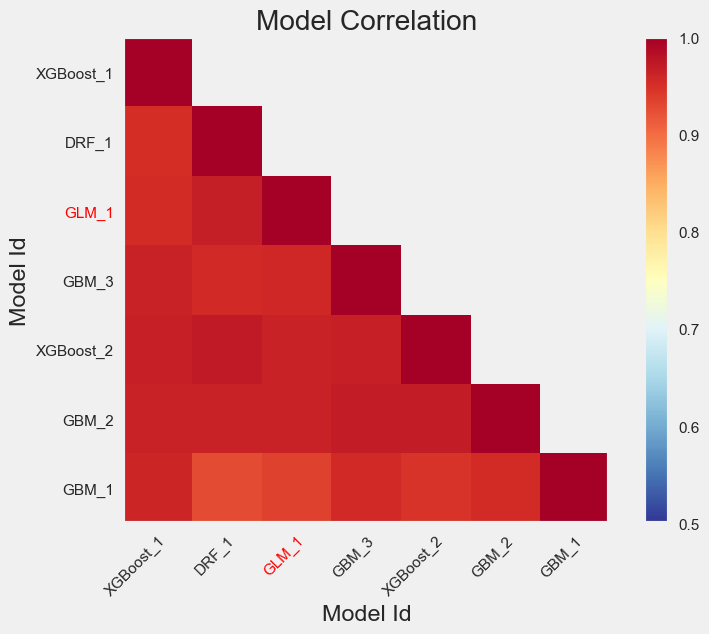

In [36]:
mc_plot = aml.model_correlation_heatmap(test_h2o, figsize = (8,6))
mc_plot

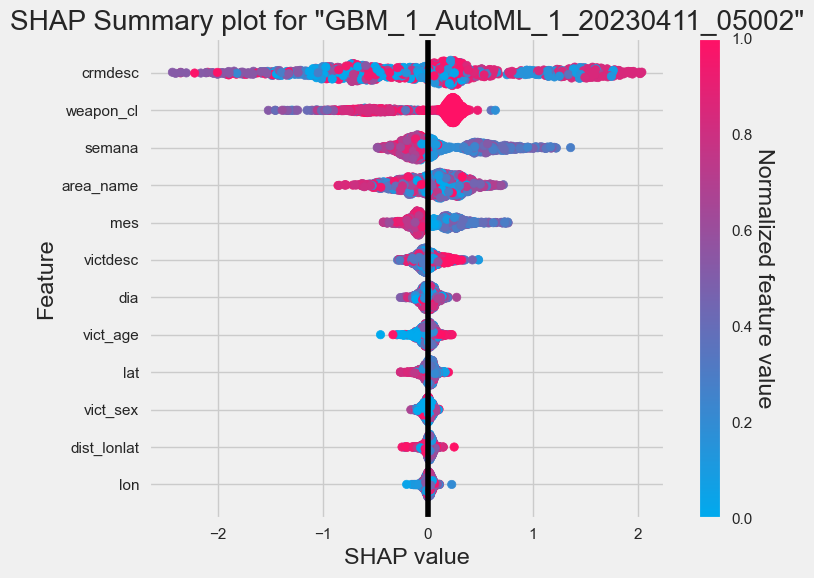

In [37]:
shap_plot = best_model.shap_summary_plot(test_h2o, figsize = (8,6))
shap_plot

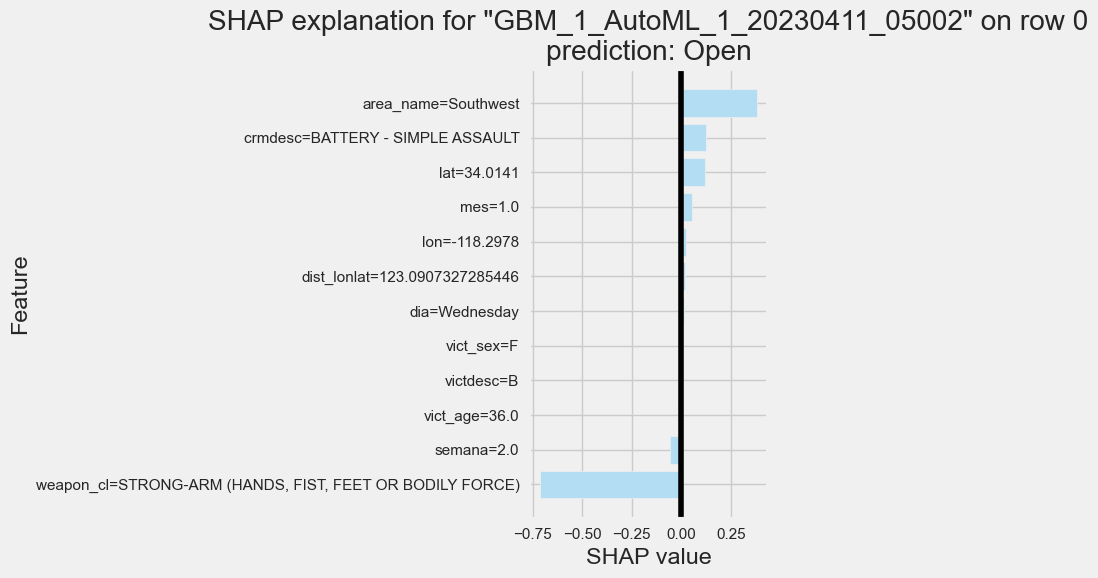

In [38]:
shapr_plot = best_model.shap_explain_row_plot(test_h2o, row_index=0, figsize = (8,6))

# SHAP Explanation

> SHAP explanation shows contribution of features for a given instance. The sum of the feature contributions and the bias term is equal to the raw prediction of the model, i.e., prediction before applying inverse link function. H2O implements TreeSHAP which when the features are correlated, can increase contribution of a feature that had no influence on the prediction.

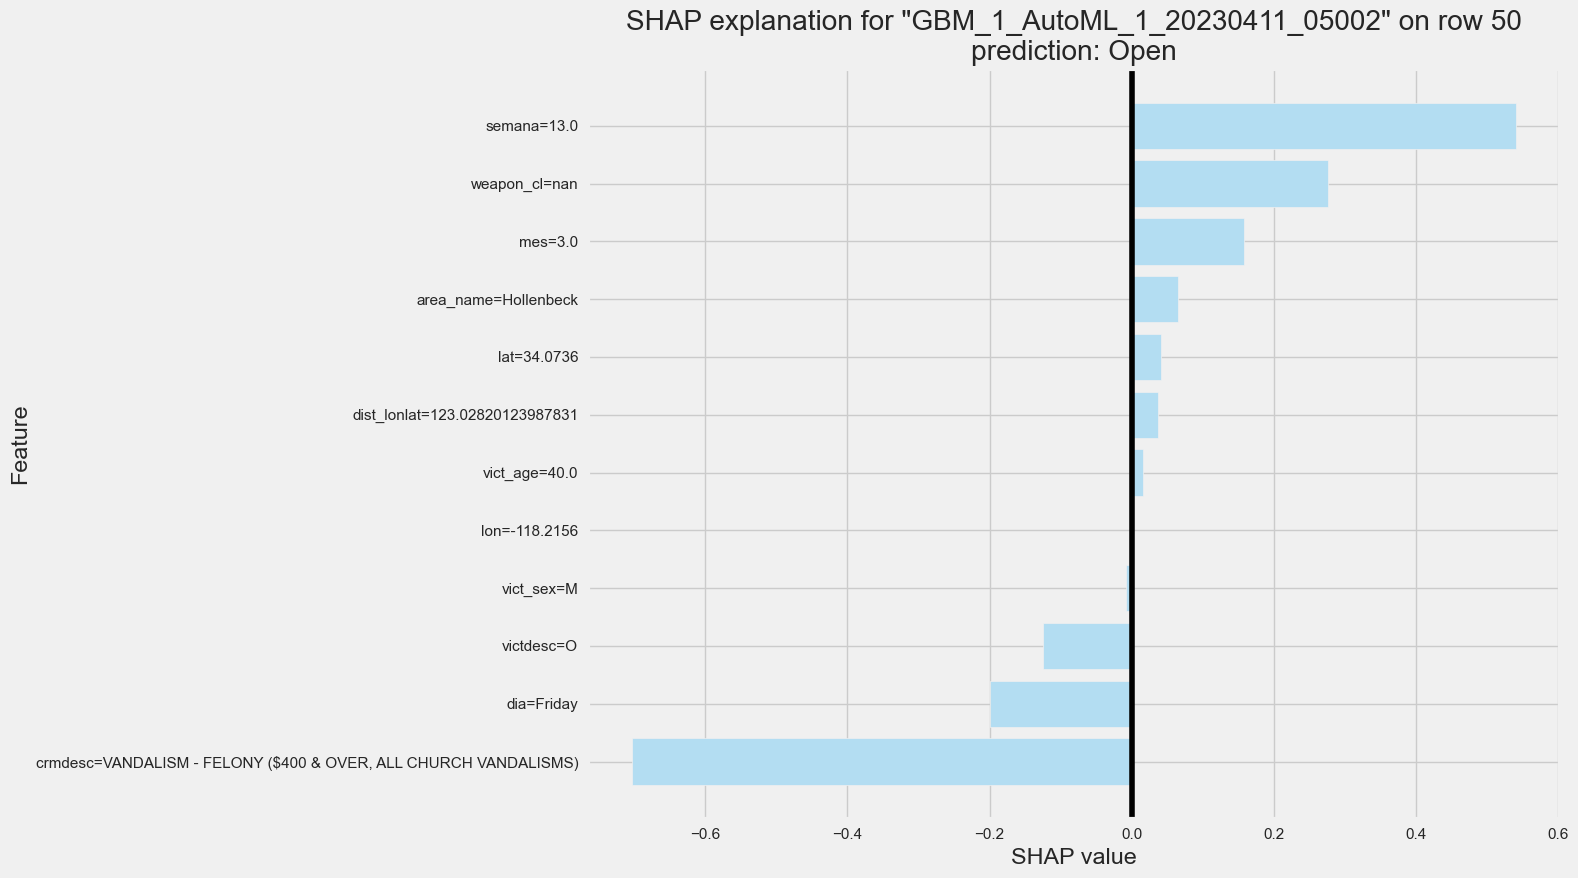

# Individual Conditional Expectation

> Individual conditional expectations (ICE) plot gives a graphical depiction of the marginal effect of a variable on the response for a given row. ICE plot is similar to partial dependence plot (PDP), PDP shows the average effect of a feature while ICE plot shows the effect for a single instance.

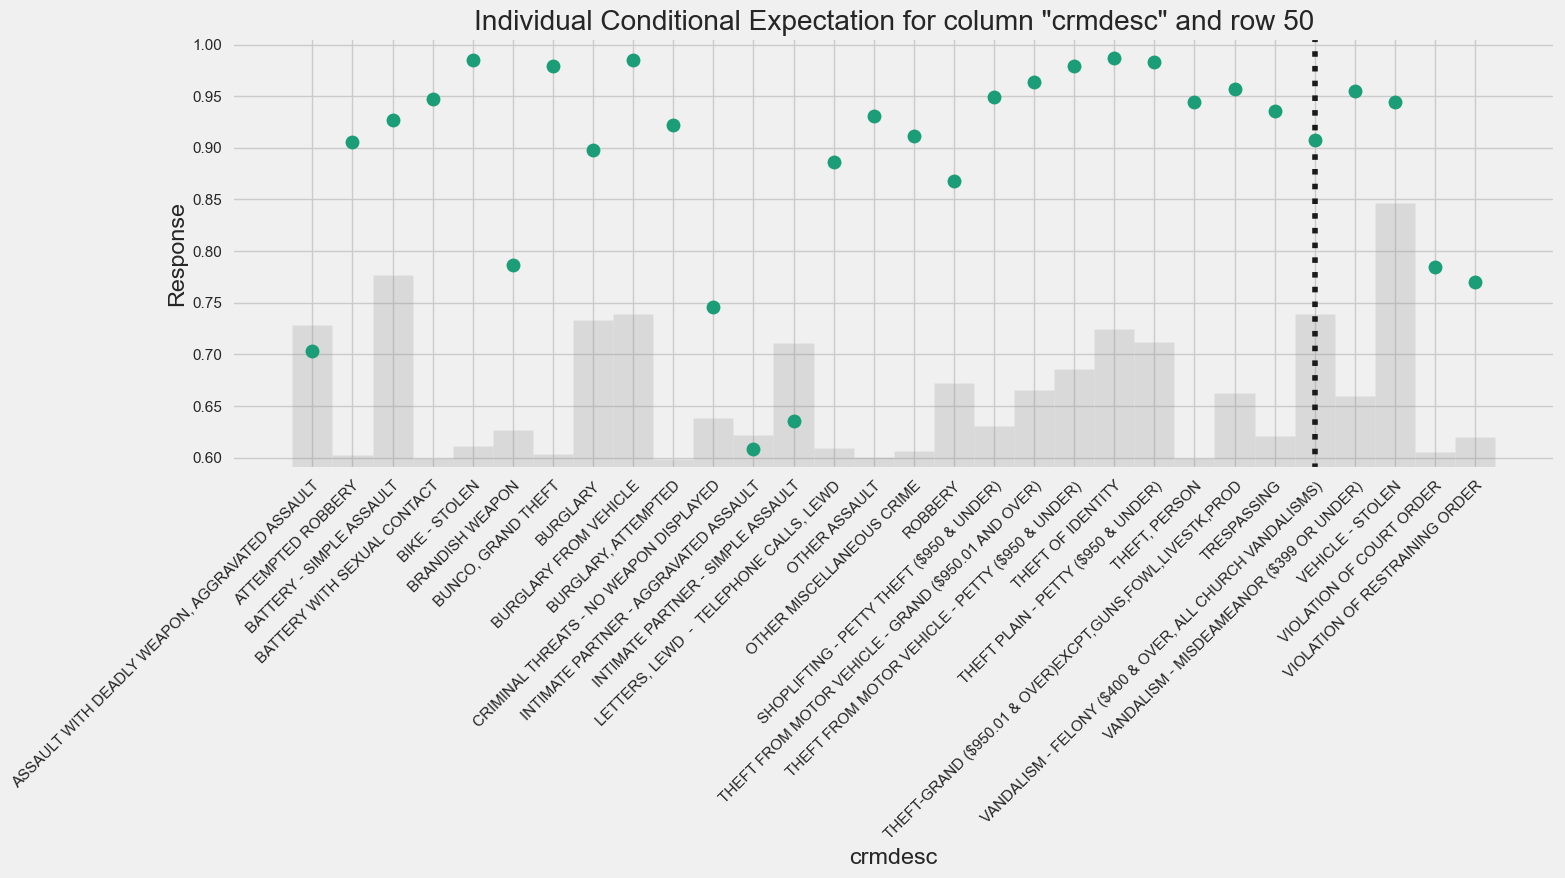

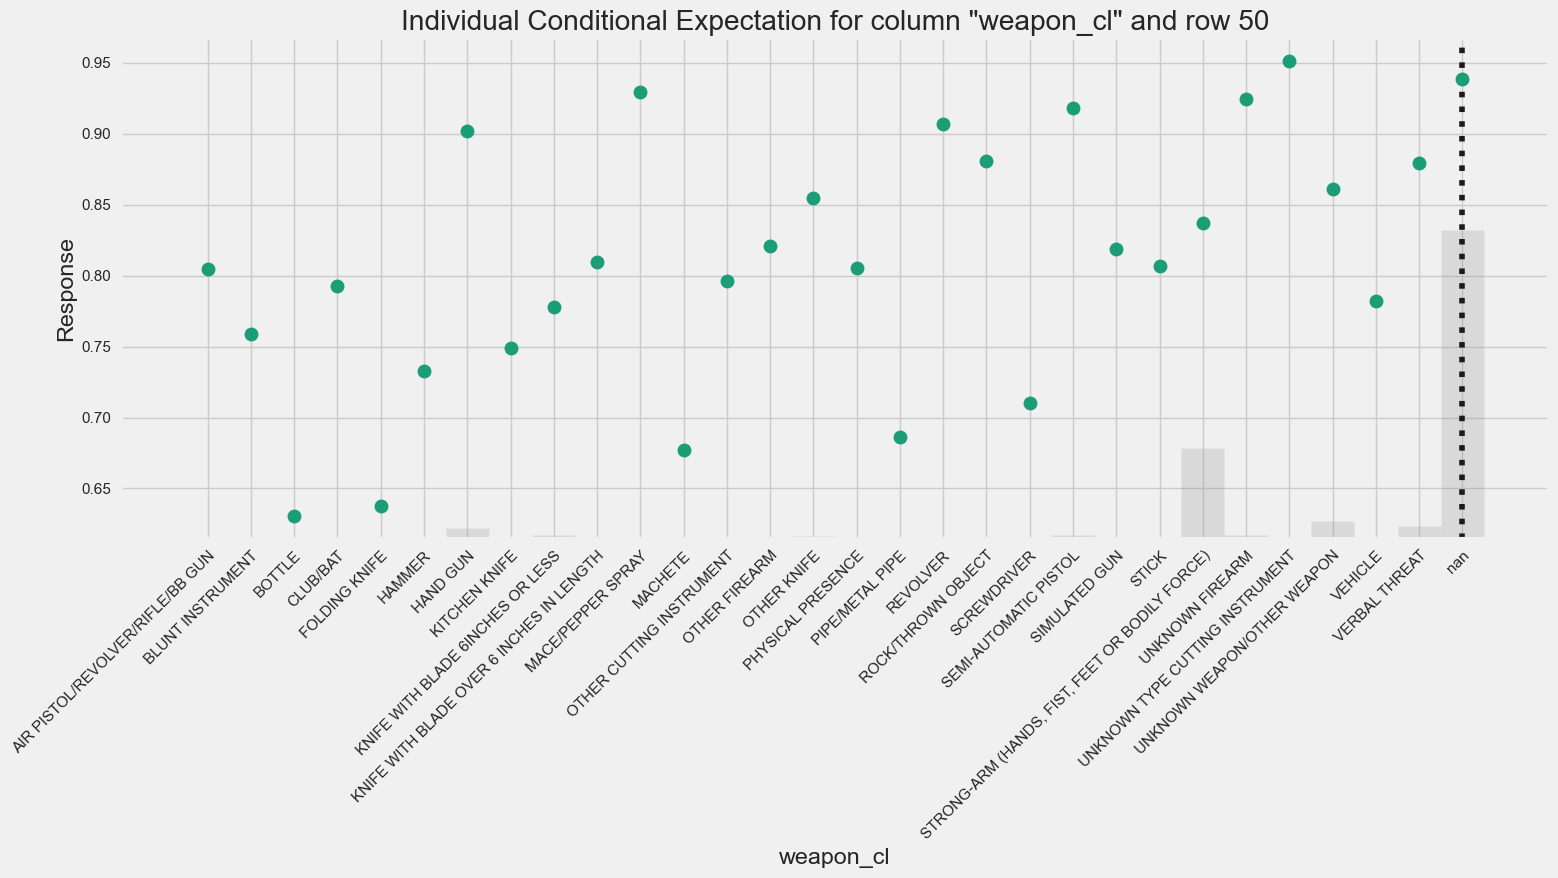

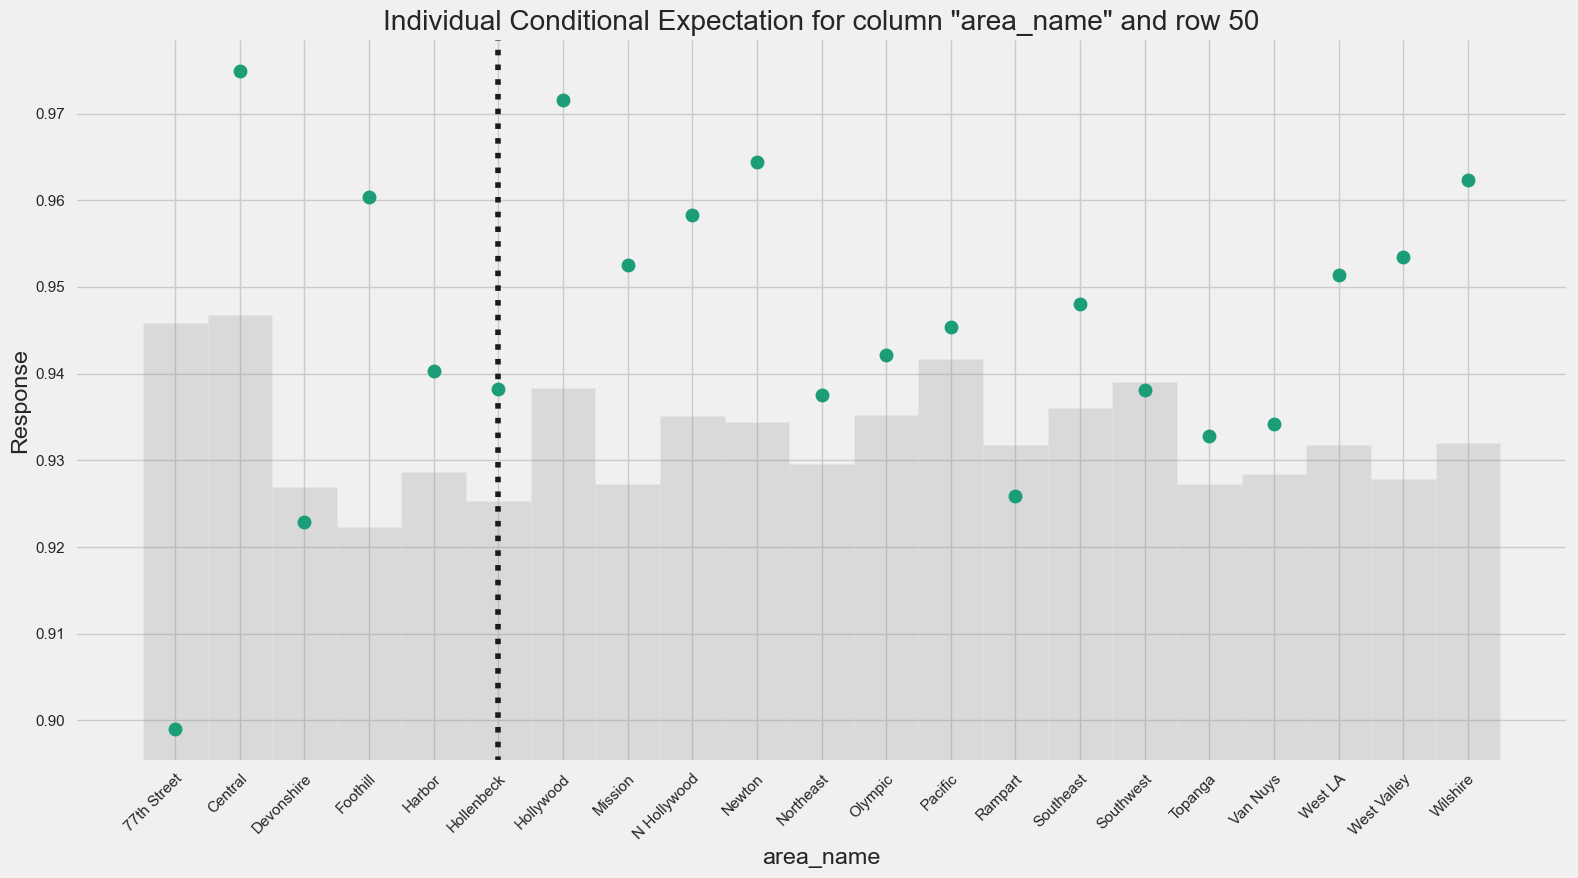

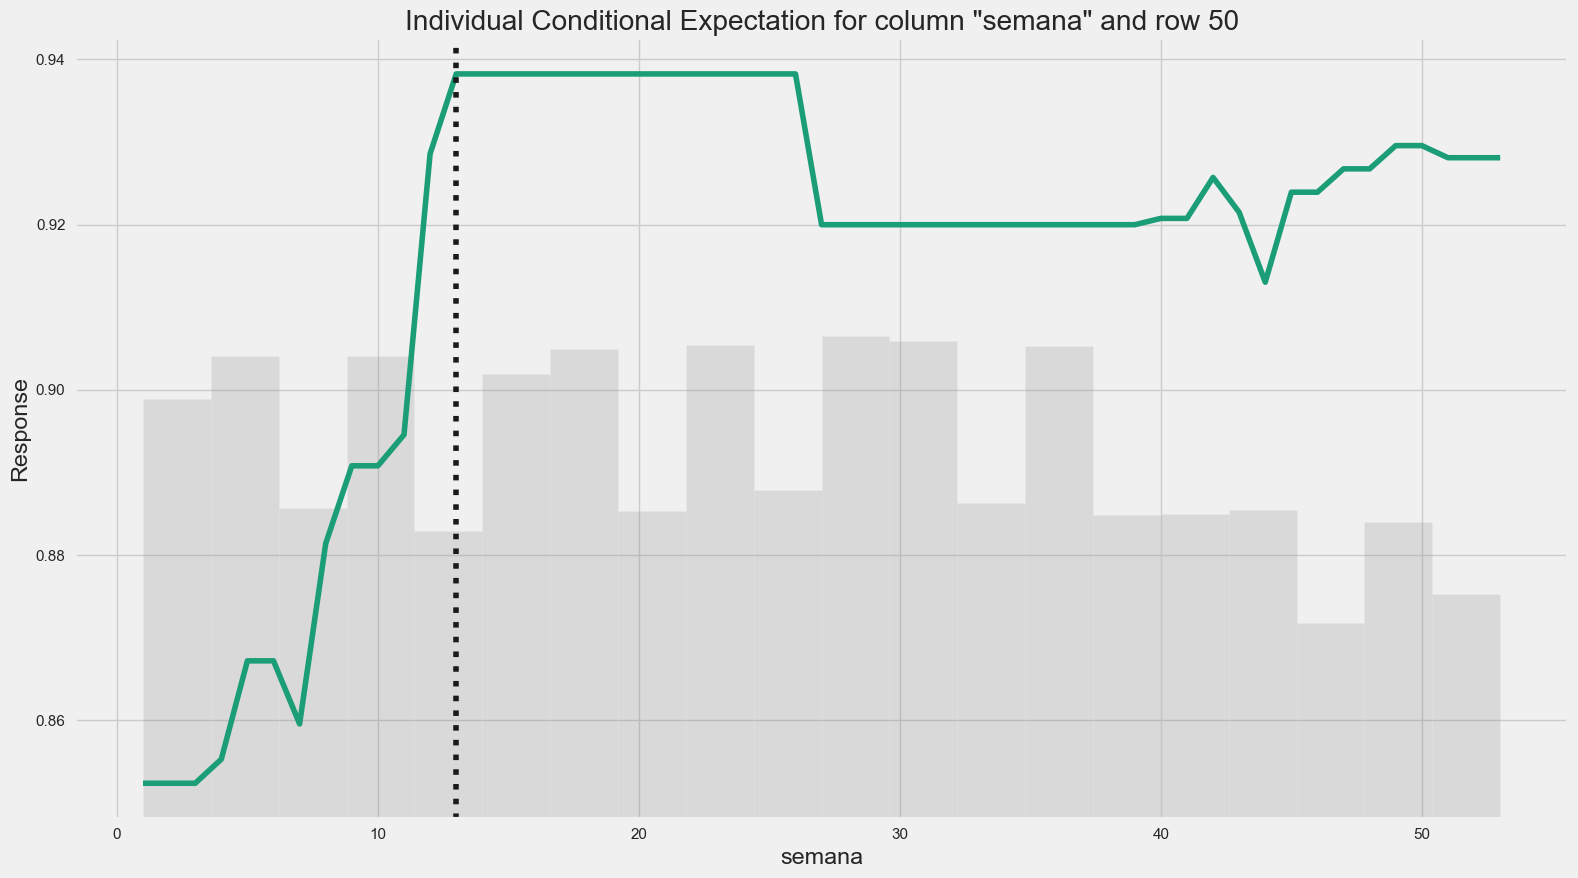

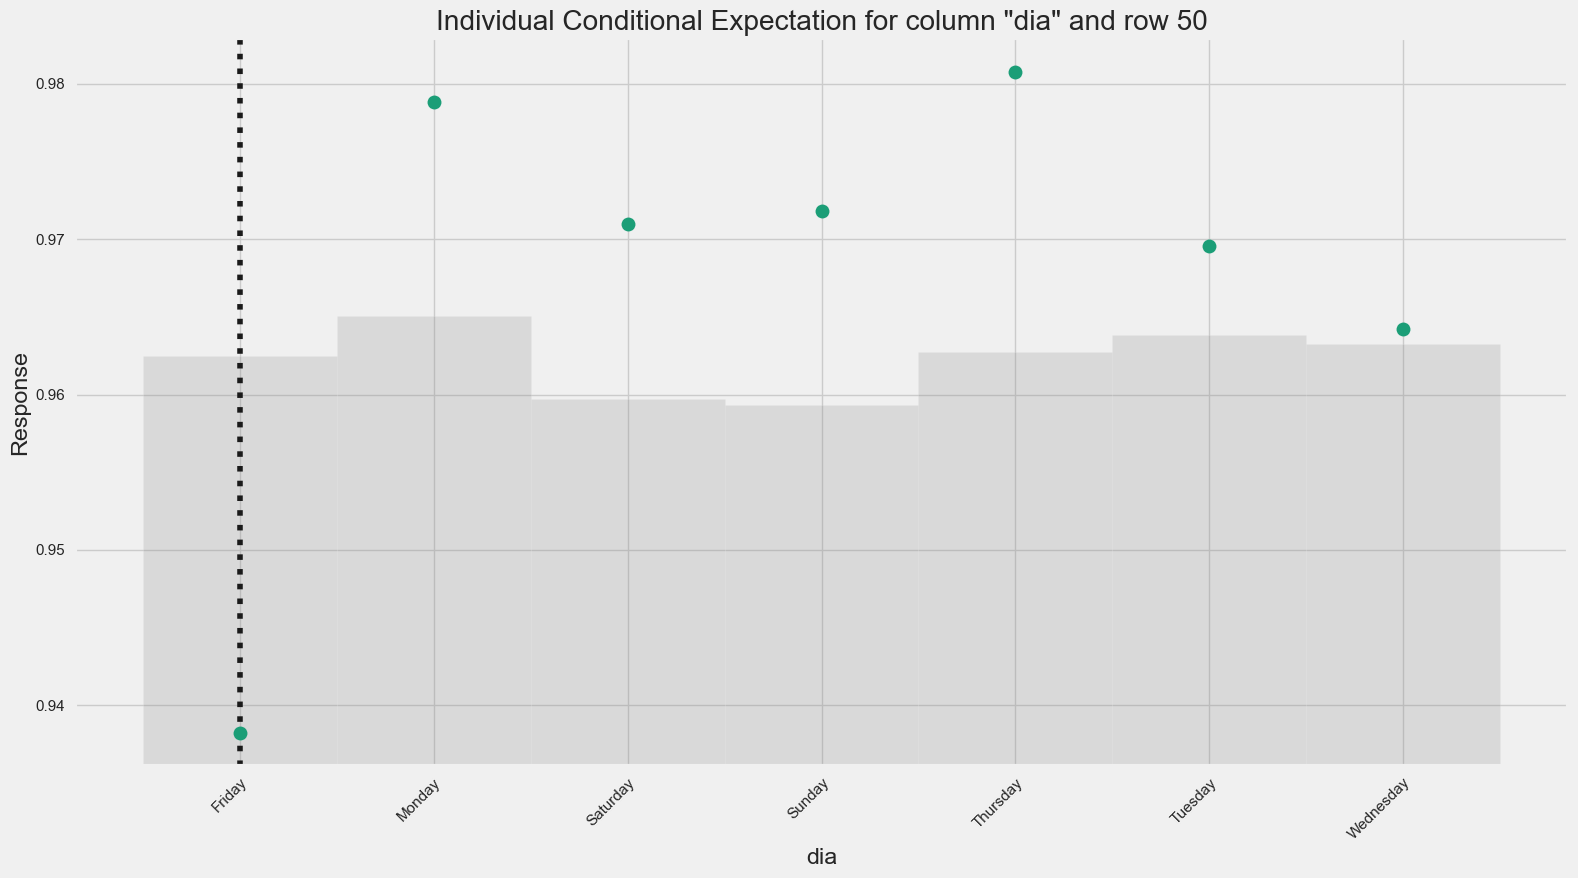

# SHAP Explanation

> SHAP explanation shows contribution of features for a given instance. The sum of the feature contributions and the bias term is equal to the raw prediction of the model, i.e., prediction before applying inverse link function. H2O implements TreeSHAP which when the features are correlated, can increase contribution of a feature that had no influence on the prediction.

# Individual Conditional Expectation

> Individual conditional expectations (ICE) plot gives a graphical depiction of the marginal effect of a variable on the response for a given row. ICE plot is similar to partial dependence plot (PDP), PDP shows the average effect of a feature while ICE plot shows the effect for a single instance.

In [39]:
best_model.explain_row(test_h2o, row_index = 50)

In [40]:
h2o.cluster().shutdown(prompt = False)

H2O session _sid_b395 closed.


In [ ]:
#H2OAutoML?